## GRG 356T Spatial Data Science and Maps
### The University of Texas at Austin, Department of Geography and the Environment
Developed by Yuhao Kang (instructor), Xihan Yao and Brody Manquen. Part of *Responsible GeoAI for Civic Futures*, supported by the Mozilla Foundation.


# Lab 8 — Network Analysis and Spatial Accessibility

## What this lab covers

| | topic | your work |
|---|---|---|
| Section 1 | Street networks and centrality | **Exercise 1** -- you write the code |
| Section 2 | Healthcare accessibility (2SFCA) | **Exercise 2** -- call a function we wrote, then map and interpret |
| Section 3 | Who gets left out? Measuring inequity | **Exercise 3** -- run two cells, then interpret the numbers |

Sections 2 and 3 use the same data: births and obstetric beds in Texas's 254 counties.

## Setup

Run the cell below **first**. It checks that every package this lab needs is
installed, and installs anything that is missing. If it installs something,
restart the kernel and run it again.


In [ ]:
# =====================================================================
# Lab 8 -- Setup: check that every package this lab needs is installed
# AND new enough. Run this cell FIRST. It is safe to re-run.
# =====================================================================

import importlib.metadata as md
import subprocess, sys

# pip package name -> minimum version this lab was written against
REQUIRED = {
    "geopandas":  "1.0",
    "contextily": "1.6",
    "shapely":    "2.0",
    "matplotlib": "3.8",
    "pandas":     "2.0",
    "numpy":      "1.26",
    "osmnx":      "2.0",
    "networkx":   "3.0",
    "requests":   "2.31",
    "segregation": "2.5",   # ready-made segregation indexes (Section 3)
}


def version_tuple(text):
    """'1.10.2' -> (1, 10, 2), so 1.10 correctly counts as newer than 1.9."""
    parts = []
    for piece in text.split(".")[:3]:
        digits = "".join(ch for ch in piece if ch.isdigit())
        parts.append(int(digits) if digits else 0)
    return tuple(parts)


problems = []
for package, minimum in REQUIRED.items():
    try:
        installed = md.version(package)
    except md.PackageNotFoundError:
        problems.append((package, minimum, "not installed"))
        continue
    if version_tuple(installed) < version_tuple(minimum):
        problems.append((package, minimum, "you have " + installed))

if problems:
    print("Installing or upgrading " + str(len(problems)) + " package(s):")
    for package, minimum, why in problems:
        print("   " + package + "  (needs >=" + minimum + ", " + why + ")")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade",
                           *[p + ">=" + m for p, m, _ in problems]])
    print("\nInstall finished.")
    if "google.colab" in sys.modules:
        print(">>> Now use the menu:  Runtime > Restart session,  then run this cell again. <<<")
        print("    Colab gives you a fresh machine every session, so this install happens")
        print("    each time you open the lab. That is expected, not an error.")
    else:
        print(">>> RESTART THE KERNEL now (Kernel > Restart), then run this cell again to confirm. <<<")
else:
    print("All " + str(len(REQUIRED)) + " required packages are present and new enough.")
    for package in REQUIRED:
        print("   " + package.ljust(18) + md.version(package))

### Imports

Every package this lab uses is imported here, once, with a note on what it is for.


In [ ]:
# Lab 8 -- every import this notebook needs, in one place.
# Run this cell once, right after Setup. If a later cell raises NameError, re-run this one.

# --- core data handling ---
import numpy as np                    # numeric arrays / summary stats on centrality and drive-time values
import pandas as pd                   # DataFrames: network stats table, Demand / Supply / ODCost CSVs
from pathlib import Path              # make the ./data folder before writing the .gpkg files

# --- Section 1: street networks and centrality ---
import osmnx as ox                    # download, project, simplify and plot OSM street networks
import networkx as nx                 # betweenness / closeness / degree centrality on those graphs
import requests                       # HTTP layer OSMnx uses to query Nominatim and Overpass

# --- Section 2: accessibility (2SFCA) geodata ---
import geopandas as gpd               # GeoDataFrames for Texas county polygons and demand points
from shapely import wkt               # read the WKT geometry strings stored in Demand_County.csv
import contextily as ctx              # Esri basemap tiles behind the accessibility maps

# --- Section 3: inequity measures ---
from segregation import singlegroup as sg   # ready-made segregation indexes, to check our own D and Gini

# --- plotting ---
import matplotlib.pyplot as plt       # figures and axes for every map in this lab
import matplotlib.cm as cm            # colormap objects when shading nodes by centrality
import matplotlib.colors as colors    # color normalization for the centrality choropleths

# Hide a harmless warning that osmnx prints while building street networks.
import warnings
warnings.filterwarnings("ignore", message="invalid value encountered", category=RuntimeWarning)

# Basemaps: if the tile server is down, the map is still drawn, just without
# the grey background.
ctx.set_cache_dir("./cache_tiles")      # reuse tiles instead of re-fetching them

def basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas):
    """Draw the Esri basemap behind `ax`, or carry on without one."""
    try:
        ctx.add_basemap(ax, source=source)
    except Exception as e:
        print(f"   (basemap tiles unavailable -- map drawn without one: {type(e).__name__})")


# Section 1 — Street Networks and Centrality

A street network is a **graph**: every intersection (or dead end) is a **node**, and every
stretch of street between two nodes is an **edge**. Once a city is a graph, a question like
"which intersection matters most?" becomes something you can compute.

This section downloads street networks with OSMnx, summarises them, and then compares three
ways of deciding which node is most *central*. In **Exercise 1** you do the same for a city
of your choice.

### OSMnx: street networks from OpenStreetMap

OSMnx (Boeing 2025) downloads the street network of any place on OpenStreetMap with one
line of code and turns it into a graph you can analyse and plot -- drive, walk or bike.

Documentation: https://github.com/gboeing/osmnx <br>
Examples: https://github.com/gboeing/osmnx-examples/tree/main/notebooks

In [ ]:
# reuse downloads already in cache/ instead of asking OpenStreetMap again
ox.settings.use_cache = True
ox.settings.log_console = False

In [ ]:
# Look up a place by name and get its boundary
atx = ox.geocoder.geocode_to_gdf("Austin, Texas, USA")
atx.to_file("./data/austin.gpkg", driver="GPKG")
atx_proj = ox.projection.project_gdf(atx)
ax = atx_proj.plot(fc="gray", ec="none")
_ = ax.axis("off")

In [ ]:
# The same works for a smaller place
ut_austin = ox.geocoder.geocode_to_gdf("UT-Austin, Texas, USA")
utatx_proj = ox.projection.project_gdf(ut_austin)
ut_austin.to_file("./data/ut_austin.gpkg", driver="GPKG")
ax = utatx_proj.plot(fc="gray", ec="none")
_ = ax.axis("off")

In [ ]:
# Several places at once: get their boundaries, save them, project and plot
place_names = [
    "Brownsville, Texas, USA",
    "McAllen, Texas, USA",
    "Harlingen, Texas, USA",
    "San Benito, Cameron County, Texas, USA", ## can use County names to be more specific
    "Edinburg, Texas, USA",
    "Mission, Hidalgo County, Texas, USA",
    "Rio Grande City, Texas, USA",
    "Raymondville, Texas, USA",
    "Pharr, Texas, USA",
    "Matamoros, Tamaulipas, Mexico",
    "Reynosa, Tamaulipas, Mexico"
]
rgv = ox.geocoder.geocode_to_gdf(place_names)
Path("data").mkdir(parents=True, exist_ok=True)
rgv.to_file("./data/rgv.gpkg", driver="GPKG")
rgv = ox.projection.project_gdf(rgv)
ax = rgv.plot(fc="gray", ec="none")
_ = ax.axis("off")

In [ ]:
# Download Austin's drive network
atx_G = ox.graph.graph_from_place("Austin, Texas, USA", network_type="drive")
# save it as a GeoPackage, then plot
ox.io.save_graph_geopackage(atx_G)
fig, ax = ox.plot.plot_graph(atx_G, node_size=0, edge_color="w", edge_linewidth=0.2)

In [ ]:
# All of Austin is big -- zoom in on campus instead.
# UT Tower coordinates. Careful: osmnx wants (latitude, longitude), the opposite
# of the Point(lon, lat) order you used in Lab 1.
location_point = (30.2861, -97.7393)

ut_G = ox.graph.graph_from_point(
    location_point,
    network_type="all",  # which kind of network: all, drive, walk, bike ...
    dist=1000,           # 1,000 m radius
    simplify=False,
)
# Notice the duplicate lines -- hard to read
fig, ax = ox.plot.plot_graph(ut_G, node_size=0, edge_color="w", edge_linewidth=0.2)

In [ ]:
# The same area, bike network only
ut_G = ox.graph.graph_from_point(
    location_point,
    network_type="bike",
    dist=1000,
    simplify=False,      # don't simplify yet
)
# Notice the duplicate lines -- hard to read
fig, ax = ox.plot.plot_graph(ut_G, node_size=0, edge_color="w", edge_linewidth=0.2)

In [ ]:
# Before simplifying, look at the nodes.
# Red = endpoints we must keep (dead ends, intersections).
# Yellow = mid-points along a street, which simplifying removes.
nc = ["r" if ox.simplification._is_endpoint(ut_G, node, None, None) else "y" for node in ut_G.nodes()]
fig, ax = ox.plot.plot_graph(ut_G, node_color=nc)

In [ ]:
# Simplify: keep only the red nodes
ut_simpG = ox.simplification.simplify_graph(ut_G) ## call the simplify_graph method
fig, ax = ox.plot.plot_graph(ut_simpG, node_color="r")

In [ ]:
# Color each street by its length.
# get_edge_colors_by_attr colors edges by an attribute; get_node_colors_by_attr does the same for nodes.
ec = ox.plot.get_edge_colors_by_attr(ut_simpG, attr="length", cmap="plasma_r")

# Every plotting option: https://osmnx.readthedocs.io/en/stable/user-reference.html#osmnx.plot.plot_graph
fig, ax = ox.plot.plot_graph(
    ut_simpG,
    bgcolor='#FFFFFF',   # background color
    node_color="w",      # node color
    node_edgecolor="k",  # node outline
    node_size=20,        # node size
    edge_color=ec,       # edge colors from above
    edge_linewidth=1,    # edge width
)

### Graph statistics

`basic_stats()` summarises a whole network in one call: how many nodes and edges it has,
how long its streets are, and how many streets meet at each intersection.

In [ ]:
# Back to all of Austin, drive network
place = "Austin, Texas, USA"
gdf = ox.geocoder.geocode_to_gdf(place)
G = ox.graph.graph_from_place(place, network_type="drive")

In [ ]:
area = ox.projection.project_gdf(gdf).union_all().area
print(area)

For density statistics, pass the network's area in square meters. Without it, `basic_stats()` skips them:

In [ ]:
# Basic network statistics (in metric units)
stats = ox.stats.basic_stats(G, area=area)
pd.Series(stats)

In [ ]:
# Two of the statistics are dictionaries: how many nodes have 1, 2, 3 ... streets.
# A node with 3 streets is a T- or Y-junction, the most common kind.
print(stats["streets_per_node_counts"])
print(stats["streets_per_node_proportions"])

To put all the statistics in one table, first unpack those two dictionaries:

In [ ]:
# unpack dicts into individual keys:values
stats = ox.stats.basic_stats(G, area=area)
for k, count in stats["streets_per_node_counts"].items(): #cycle through each dictionary
    stats[f"{k}way_int_count"] = count
for k, proportion in stats["streets_per_node_proportions"].items():
    stats[f"{k}way_int_prop"] = proportion

# drop the original dictionaries
del stats["streets_per_node_counts"]
del stats["streets_per_node_proportions"]

# load as a pandas dataframe
pd.DataFrame(pd.Series(stats, name="value")).round(3)

### Centrality

Centrality scores how important each node is to the network. "Important" can mean several
things, so we use three measures, and each asks a different question:

| measure | the question it asks | it tends to find |
|---|---|---|
| **Betweenness** | how many shortest paths pass through here? | bottlenecks and bridges |
| **Closeness** | how near is every other node? | the middle of the network |
| **Degree** | how many streets meet here? | busy junctions |

The three usually crown **different** nodes. In the toy town below -- a grid, a river, one
bridge, and a roundabout with five dead ends -- each measure picks a different intersection:

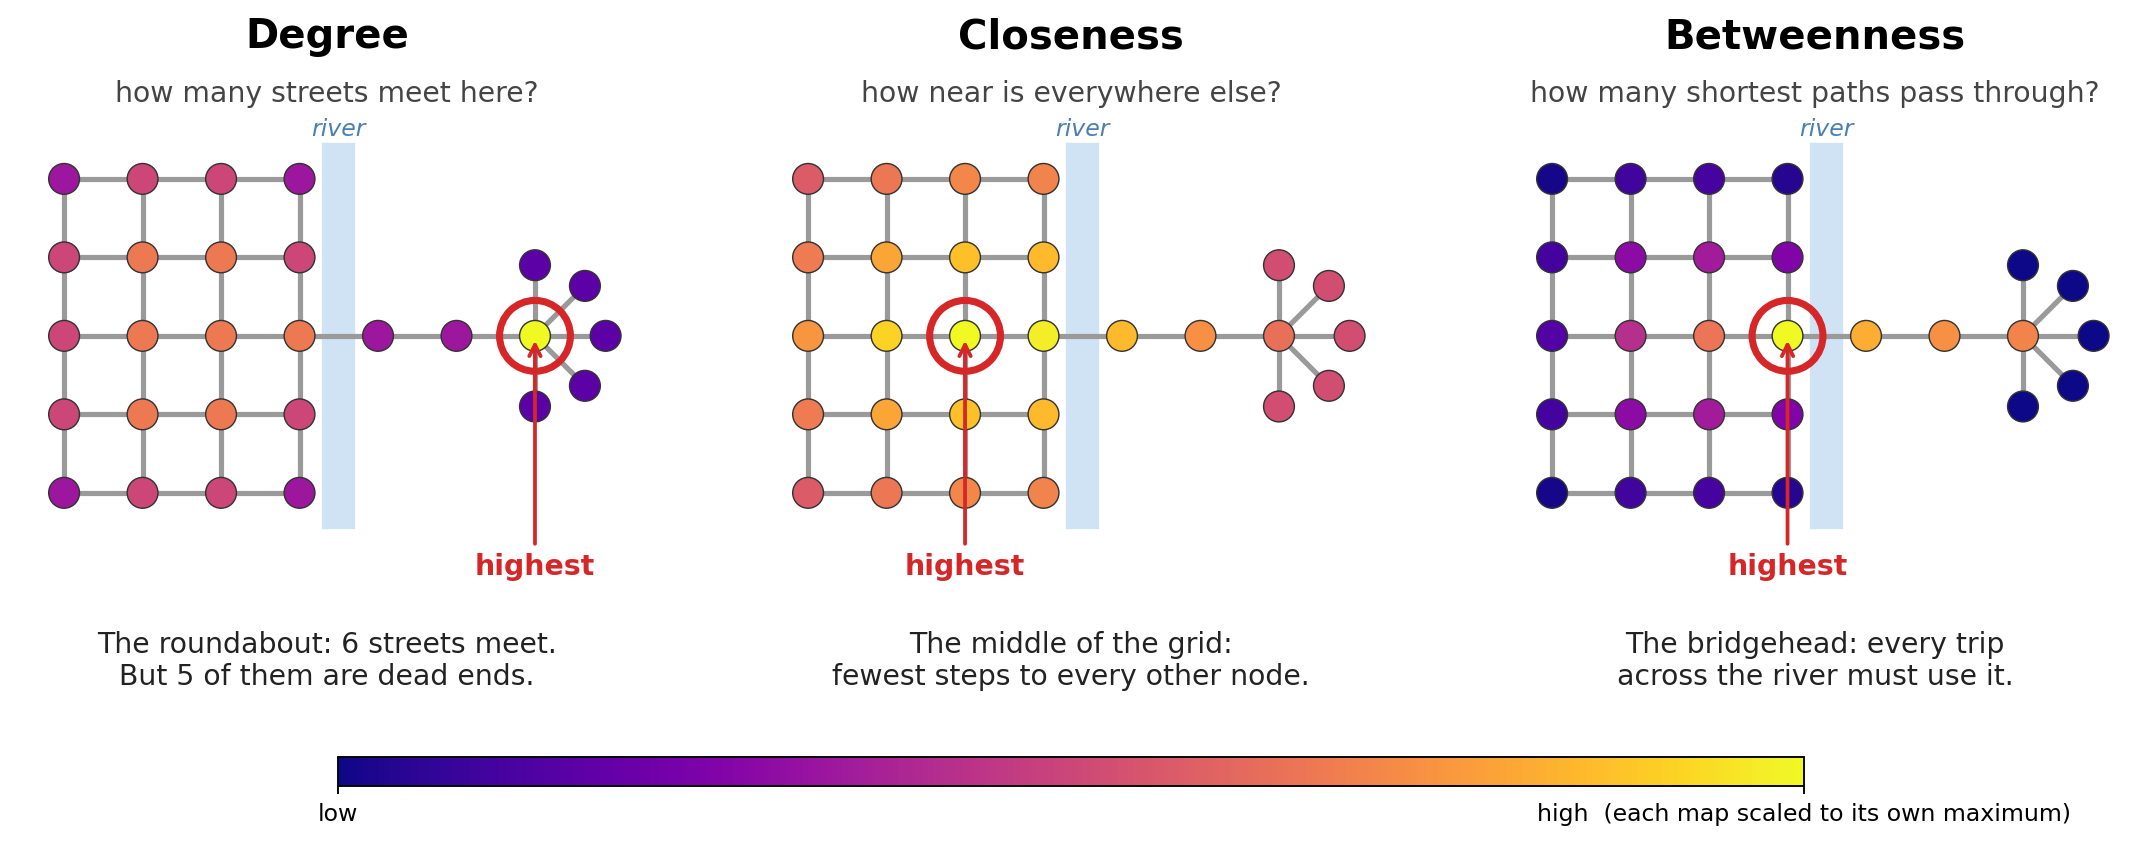

Explaining why they disagree on *your* city is what Exercise 1 asks for. These are formulas,
not machine learning: the same network always gives the same numbers.

We start with the hiking trails of Big Bend National Park, a small network where all three
measures finish in seconds.

In [ ]:
# Let's find hiking paths in Big Bend National Park -- a small, sparse network,
# so the three centrality measures below finish in seconds
place = "Big Bend National Park"
gdf = ox.geocoder.geocode_to_gdf(place)
G = ox.graph.graph_from_place(place, network_type="walk")
fig, ax = ox.plot.plot_graph(
    G,
    bgcolor='#111111', ## you can change the background color (white)
    node_color="r", #change node color
    node_edgecolor="k", #change node edge color
    node_size=15, #change node size
    edge_color="w", #set edge color
    edge_linewidth=1, #set edge width
)

In [ ]:
# area in square km
area = ox.projection.project_gdf(gdf).union_all().area
print(area/1000000) #print it in sq km

#### Betweenness

Betweenness centrality asks: **how often does the shortest path between two other nodes pass through this one?** It is the share of all shortest paths in the network that run through the node. A node with high betweenness is a bottleneck.

In [ ]:
# Betweenness, computed with NetworkX (https://networkx.org)

bc = nx.betweenness_centrality(ox.convert.to_digraph(G), weight="length") 
max_node, max_bc = max(bc.items(), key=lambda x: x[1])
max_node, max_bc

The second number is that node's betweenness. Read it as a share: at about 0.37, more than a third of all shortest paths between Big Bend trail nodes run through this one node.

In [ ]:
# Highlight that node
nc = ["r" if node == max_node else "w" for node in G.nodes]
ns = [80 if node == max_node else 15 for node in G.nodes]
fig, ax = ox.plot.plot_graph(G, node_size=ns, node_color=nc, node_zorder=2)

This node sits right in the middle of the trail network, as you would expect.

In [ ]:
# Now color every node by its betweenness
# add the betweenness centrality values as new node attributes, then plot
nx.set_node_attributes(G, bc, "bc")
nc = ox.plot.get_node_colors_by_attr(G, "bc", cmap="Greens")
fig, ax = ox.plot.plot_graph(
    G,
    bgcolor="black",
    node_color=nc,
    node_size=20,
    node_zorder=2,
    edge_linewidth=0.5,
    edge_color="w",
)

Betweenness picks out several choke points across the park, not just one.

#### Closeness

Closeness centrality asks: **how near is this node to every other node?** It is 1 divided by the average shortest-path distance from the node to all the others (here counted in street segments). A node in the middle of the network scores high; a node at the edge scores low.

In [ ]:
# Closeness (on a version of G without duplicate parallel edges)
cc = nx.closeness_centrality(ox.convert.to_digraph(G))
max_node, max_cc = max(cc.items(), key=lambda x: x[1])
max_node, max_cc

In [ ]:
# Highlight that node
nc = ["r" if node == max_node else "w" for node in G.nodes]
ns = [80 if node == max_node else 15 for node in G.nodes]
fig, ax = ox.plot.plot_graph(G, node_size=ns, node_color=nc, node_zorder=2)

In [ ]:
# Now color every node by its closeness
# add the closeness centrality values as new node attributes, then plot
nx.set_node_attributes(G, cc, "cc")
nc = ox.plot.get_node_colors_by_attr(G, "cc", cmap="Greens")
fig, ax = ox.plot.plot_graph(
    G,
    bgcolor="black",
    node_color=nc,
    node_size=20,
    node_zorder=2,
    edge_linewidth=0.5,
    edge_color="w",
)

#### Degree

Degree centrality asks: **how many streets meet here?** It is the number of nodes this node
connects to, divided by the number of nodes in the whole network. Because of that division
the values are tiny on a large network -- compare nodes with each other, not with a fixed
scale.

In [ ]:
# Degree (on a version of G without duplicate parallel edges)
dc = nx.degree_centrality(ox.convert.to_digraph(G))
max_node, max_dc = max(dc.items(), key=lambda x: x[1])
max_node, max_dc

In [ ]:
# Highlight that node
nc = ["r" if node == max_node else "w" for node in G.nodes]
ns = [80 if node == max_node else 15 for node in G.nodes]
fig, ax = ox.plot.plot_graph(G, node_size=ns, node_color=nc, node_zorder=2)

In [ ]:
# Now color every node by its degree
# add the degree centrality values as new node attributes, then plot
nx.set_node_attributes(G, dc, "dc")
nc = ox.plot.get_node_colors_by_attr(G, "dc", cmap="Greens")
fig, ax = ox.plot.plot_graph(
    G,
    bgcolor="black",
    node_color=nc,
    node_size=20,
    node_zorder=2,
    edge_linewidth=0.5,
    edge_color="w",
)

# Exercise 1 — Centrality in Your City

**What you do:** write the code yourself, in the cell below.<br>
**Hand in:** 6 maps and 1 paragraph.

1. Download a **drive** network for a city of your choice (or part of one) with OSMnx. If
   a place name gives an error, look up its exact name at https://www.openstreetmap.org/
2. Compute **betweenness**, **closeness** and **degree** centrality, the same way the Big
   Bend example above does.
3. For each measure, make **two maps** -- six in total:
   - the network with the **highest** and the **lowest** node highlighted;
   - every node coloured by its centrality value.
4. *In a paragraph (2-4 sentences or more): what patterns do the three measures show, how
   do they differ from one another and why, and what does that say about how your city is
   laid out?*

### ⚠️ Pick something small enough to finish

`betweenness_centrality` gets slow quickly as the network grows:

| nodes | betweenness takes about |
|---:|---|
| 2,600 | 16 seconds |
| 5,700 | 1.5 minutes |
| 11,000 | 7.5 minutes |
| 45,000 | **3 hours** |

**All of Austin is that last row**, and so is any large city. Take part of it instead:

```python
G = ox.graph.graph_from_address("Austin, Texas, USA", dist=3000, network_type="drive")
print(len(G.nodes), "nodes")      # aim for under ~5,000
```

`dist=3000` means 3 km out from that address -- about 2,600 nodes for central Austin. A
small city such as San Marcos you can take whole. **Print `len(G.nodes)` before you
compute anything**; if it is in the tens of thousands, make `dist` smaller.

If a download fails or times out, wait a moment and run the cell again. The
OpenStreetMap servers are free and often busy -- it is usually not your code.

In [ ]:
# ============================================================
# YOUR CODE FOR EXERCISE 1 GOES IN THIS CELL (six maps)
# Delete the raise line below, then write your code in its place.
# ============================================================

raise NotImplementedError("Delete this line and write your code here.")

### Your answers — Exercise 1

*Double-click this cell and write your paragraph here.*

# Section 2 — Healthcare Accessibility with 2SFCA

Section 2 uses networks for a real problem: **how easily can people reach healthcare?** Poor
access leads to worse health outcomes, and it usually falls hardest on people who are
already disadvantaged. We estimate an obstetric-care accessibility score for every county in
Texas with the **Two-Step Floating Catchment Area (2SFCA)** method (Radke & Mu 2000;
Luo & Wang 2003).

### The idea in plain words

Dividing "beds in my county" by "births in my county" fails twice: people cross county lines
to give birth, and the same beds serve several counties at once. 2SFCA fixes both by drawing
a travel-time circle of radius $d_0$ **twice**:

1. **Around each hospital -- competition.** Share its beds among *every* birth that can reach
   it. The result, $R_j$, is beds per birth at that hospital.
2. **Around each county -- choice.** Add up the $R_j$ of every hospital the county can reach.
   The result, $A_i$, is the county's accessibility score.

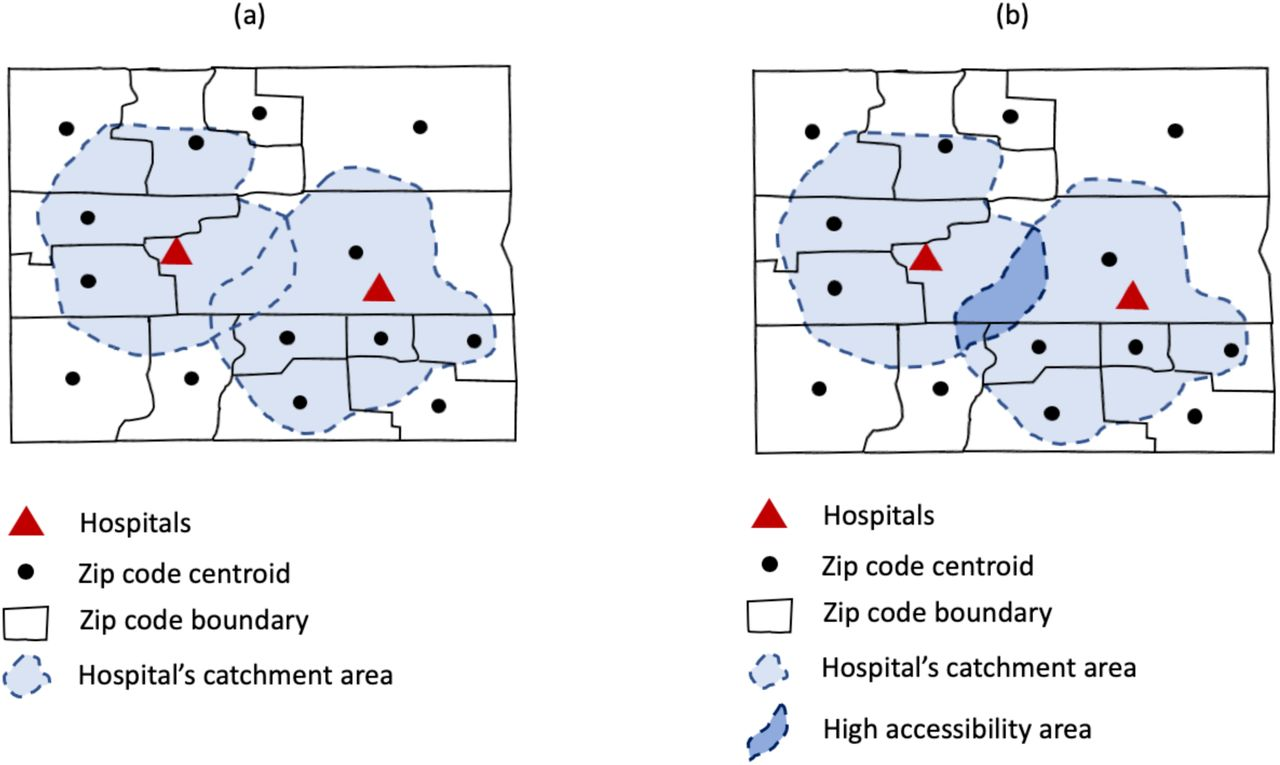

A county with no hospital can still score above zero if it can reach one, and a county that
can reach none scores 0 however many births it has. Parts C and D below write each step out
with its formula.

### How this section is organised

| part | what happens |
|---|---|
| A | load births (demand), beds (supply) and county-to-county drive times |
| B | choose the travel threshold $d_0$ |
| C | 2SFCA step 1: a beds-per-birth ratio $R_j$ for each county with beds |
| D | 2SFCA step 2: add up the reachable $R_j$ into each county's score $A_i$ |
| E | map the scores, and list what this analysis cannot see |

## Part A — Load the data

Three files in the `data` folder:
- `Demand_County.csv` -- demand: births in each of Texas's 254 counties
- `Supply_County.csv` -- supply: obstetric beds, aggregated to the county
- `ODCost_County_Matrix.csv` -- a precomputed matrix of drive times between every pair of counties

In [ ]:
# Load Demand data
demand_df = pd.read_csv("data/Demand_County.csv")
demand_df["geometry"] = gpd.GeoSeries.from_wkt(demand_df["geometry"])
demand_gdf = gpd.GeoDataFrame(demand_df, geometry="geometry", crs=4326)
demand_df.head()

In [ ]:
# Reproject to Web Mercator for basemap
demand_web = demand_gdf.to_crs(epsg=3857)

# Quick map with basemap
fig, ax = plt.subplots(figsize=(10, 8))
demand_web.plot(
    ax=ax,
    markersize=10,
    alpha=0.7,
    color="green",
    label="County Demand Locations"
)

basemap(ax)

ax.set_title("Demand Locations (County Centroids)", fontsize=14)
ax.legend()
plt.show()

- `Demand_FIPS`: the FIPS code for each county in Texas (they all begin `48`)
- `County_Name`: the county name
- `Demand_Births`: the demand measure (we will use as $D_k$)
- `geometry`: a county reference point

We now have a spatial dataset of all 254 Texas counties.

> **About the reference point.** Each county's point is placed where its births are
> (a birth-weighted centre), not at its geometric centre, because travel time should be
> measured from where the mothers live. The 14 counties with no births use the geometric
> centre instead.


### Load Supply Data

`Supply_County.csv` is the supply side, already aggregated to the county level:

- `Demand_FIPS`: county FIPS code -- this is what we join on
- `OBBD`: number of obstetric beds in that county (our supply measure, $S_j$)

The file lists only counties that **have** obstetric beds. The merge below uses
`how="left"` and fills the missing counties with 0, so they stay in the data.

In [ ]:
# Load supply data
supply_df = pd.read_csv("data/Supply_County.csv")
supply_df.head()

In [ ]:
# Join supply to demand
county_access = demand_gdf.merge(supply_df, on="Demand_FIPS", how="left").fillna(0)

county_access.head()

In [ ]:
# Load county boundaries. EPSG:3083 (Texas Albers) is the right projection
# for measuring and mapping areas within Texas.
tx_counties = gpd.read_file("data/tx_counties.geojson").to_crs(epsg=3083)
tx_counties["FIPS"] = tx_counties["FIPS_ST_CNTY_CD"].astype(str)

county_access["Demand_FIPS"] = county_access["Demand_FIPS"].astype(str)

# Merge with aggregated demand and supply
tx_counties = tx_counties.merge(county_access, left_on="FIPS", right_on="Demand_FIPS",
                                how="left").fillna(0)
tx_counties = tx_counties.set_geometry("geometry_x")
print(f"{len(tx_counties)} counties | births {tx_counties.Demand_Births.sum():,.0f} "
      f"| beds {tx_counties.OBBD.sum():,.0f}")


In [ ]:
# Plot county-level Demand
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

tx_counties.plot(
    column="Demand_Births",
    cmap="Blues",
    linewidth=0.8,
    edgecolor="gray",
    legend=True,
    ax=ax[0]
)
ax[0].set_title("County-Level Demand (Births)")

tx_counties.plot(
    column="OBBD",
    cmap="Reds",
    linewidth=0.8,
    edgecolor="gray",
    legend=True,
    ax=ax[1]
)
ax[1].set_title("County-Level Supply (OBBD)")

for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Compare the two maps

Births follow the metros -- Houston, Dallas-Fort Worth, San Antonio, Austin and the
Rio Grande Valley. Beds follow them too, but much more sharply: **101 of Texas's 254
counties have any obstetric beds at all**, and the other 153 have none.

West Texas and the Panhandle are nearly empty on both maps. A map of beds alone cannot
tell you whether there are *enough* beds -- for that you need demand and travel time in
the same calculation, which is what 2SFCA does.


### Load the OD Cost Matrix

`data/ODCost_County_Matrix.csv` holds the travel cost between **every pair of Texas
counties** -- 254 x 254 = 64,516 rows:

| column | meaning |
|---|---|
| `origin_FIPS` | the county people travel **from** (demand) |
| `dest_FIPS` | the county they travel **to** (supply) |
| `Drive_Minutes` | driving time between the two county reference points |
| `Drive_Miles` | driving distance |
| `Straight_Miles` | straight-line ("as the crow flies") distance |

We will use `Drive_Minutes` as the travel cost $d_{kj}$.

> **Why counties and not individual hospitals?** The source data tracks individual
> patients, so a small hospital in a small community could identify the people in it. The
> data was therefore added up to counties before it was shared -- a common privacy limit in
> health data. Limitation 1 below explains what it costs us.

In [ ]:
# =====================================================================
# Written for you -- load the travel-time matrix and line it up with the
# demand and supply tables. You do not need to change anything here.
# =====================================================================

od_long = pd.read_csv("data/ODCost_County_Matrix.csv")
print(f"OD matrix: {len(od_long):,} county pairs")

# pivot the long table into a square matrix: rows = origin, columns = destination.
# cost.loc[k, j] is then the drive time in minutes from county k to county j.
cost = od_long.pivot(index="origin_FIPS", columns="dest_FIPS", values="Drive_Minutes")

# put the demand and supply tables in the same county order as the matrix,
# so that row i of every array below is the same county
fips   = cost.index.astype(int).to_numpy()
aligned = county_access.copy()
aligned["Demand_FIPS"] = aligned["Demand_FIPS"].astype(int)
lookup = aligned.set_index("Demand_FIPS").reindex(fips)
assert not lookup["Demand_Births"].isna().any(), "county alignment failed"

births = lookup["Demand_Births"].to_numpy(dtype=float)   # D_k, demand
beds   = lookup["OBBD"].to_numpy(dtype=float)            # S_j, supply
travel = cost.to_numpy(dtype=float)                      # d_kj, minutes

print(f"aligned {len(fips)} counties | births {births.sum():,.0f} | obstetric beds {beds.sum():,.0f}")
print(f"travel time: {travel[travel > 0].min():.0f} to {travel.max():.0f} minutes between counties")

## Part B — Choose the travel threshold $d_0$

$d_0$ is the furthest someone is assumed to be willing (or able) to travel. Everything
inside it counts as "reachable"; everything outside does not.

There is no single correct value. Studies of obstetric access commonly use 30 or 60
minutes. We start at **60 minutes** and you will test other values in Exercise 2.

In [ ]:
# What do the travel times actually look like?

off_diagonal = travel[~np.eye(len(fips), dtype=bool)]
print(f"county-to-county drive times (minutes)")
print(f"   shortest {off_diagonal.min():6.0f}")
print(f"   median   {np.median(off_diagonal):6.0f}")
print(f"   longest  {off_diagonal.max():6.0f}   <- the Panhandle to the Rio Grande Valley")

threshold = 60      # d_0, in minutes
reachable = travel <= threshold          # reachable[k, j] -> can county k reach county j?
print(f"\nAt d_0 = {threshold} min, a county can reach {reachable.sum(axis=1).mean():.1f} other counties on average.")


## Part C — 2SFCA step 1: beds per birth at each county with beds

For every county $j$ that **has** obstetric beds, find all counties $k$ whose residents
can reach it within $d_0$, add up their births, and divide the beds by that total:

$$
R_j = \frac{S_j}{\sum_{k \,:\, d_{kj} \leq d_0} D_k}
$$

The denominator counts **everyone who can reach those beds**, not just county $j$'s own
births. A hospital that serves five large counties is less available than one with the
same number of beds that serves one small county.

In [ ]:
# --- Step 1 of 2SFCA -------------------------------------------------
# reachable[k, j] is True when county k can reach county j within d_0.
# Summing births DOWN each column j gives the demand competing for county j's beds.

demand_on_j = reachable.T @ births          # for each j: sum of D_k over reachable k

# R_j = S_j / that total.  Counties with no reachable demand get 0 rather than NaN.
R = np.divide(beds, demand_on_j, out=np.zeros_like(beds), where=demand_on_j > 0)

step1 = pd.DataFrame({
    "County_Name": lookup["County_Name"].to_numpy(),
    "OBBD": beds,
    "Own_Births": births,
    "Competing_Births": demand_on_j,
    "R_j": R,
}).sort_values("R_j", ascending=False)

print(f"{(beds > 0).sum()} counties have obstetric beds; the other {(beds == 0).sum()} have R_j = 0.\n")
print("Highest supply-to-demand ratios:")
print(step1.head(5).to_string(index=False))

## Part D — 2SFCA step 2: add up what each county can reach

This step turns the supply ratios into an **accessibility score**. For every county $i$,
add up the $R_j$ of every county it can reach within $d_0$:

$$
A_i = \sum_{j \,:\, d_{ij} \leq d_0} R_j
$$

A high $A_i$ means a lot of obstetric capacity is within reach, compared with everyone
else who needs it. Look in the output below for counties with no beds of their own that
still score above zero.

In [ ]:
# --- Step 2 of 2SFCA -------------------------------------------------
# Summing R_j ACROSS each row i gives the accessibility of county i.

A = reachable @ R

access = pd.DataFrame({
    "Demand_FIPS": fips,
    "County_Name": lookup["County_Name"].to_numpy(),
    "OBBD": beds,
    "Demand_Births": births,
    "Access_Score": A,
})

print("Best-served counties:")
print(access.nlargest(5, "Access_Score").to_string(index=False))

no_access = access[access.Access_Score == 0]
print(f"\n{len(no_access)} counties have NO obstetric beds within {threshold} minutes,")
print(f"accounting for {no_access.Demand_Births.sum():,.0f} births "
      f"({100 * no_access.Demand_Births.sum() / births.sum():.1f}% of the state).")

## Part E — Map the accessibility scores

Every county now has a score, including the ones with no hospital.

In [ ]:
# =====================================================================
# Written for you -- join the scores to the county boundaries and map them.
# =====================================================================

tx = gpd.read_file("data/tx_counties.geojson")
tx["Demand_FIPS"] = tx["FIPS_ST_CNTY_CD"].astype(int)
tx_access = tx.merge(access, on="Demand_FIPS", how="left").to_crs(epsg=3857)

fig, ax = plt.subplots(1, 2, figsize=(17, 8))

tx_access.plot(column="Access_Score", cmap="viridis", legend=True, linewidth=0.4,
               edgecolor="gray", ax=ax[0],
               legend_kwds={"label": f"2SFCA score (beds per birth within {threshold} min)"})
ax[0].set_title(f"Obstetric accessibility, $d_0$ = {threshold} min")

# highlight the counties with no access at all
tx_access.plot(color="#eeeeee", edgecolor="gray", linewidth=0.4, ax=ax[1])
tx_access[tx_access.Access_Score == 0].plot(color="crimson", edgecolor="gray",
                                            linewidth=0.4, ax=ax[1])
ax[1].set_title(f"No obstetric beds within {threshold} minutes")

for a in ax:
    basemap(a)
    a.set_axis_off()
plt.tight_layout(); plt.show()


### Limitations of this analysis

Every accessibility study makes assumptions. Here are ours. You will need to list your
own in your final project.

**1. Counties, not hospitals or homes.** Everyone in a county is placed at one point, and so
is every hospital. That describes a small urban county well and a huge West Texas one badly
-- Brewster County is larger than Connecticut -- so the error is largest where access is
already worst, and it **understates** how far some people really travel.

**2. Travel times assume a car and no traffic.** They come from a routing engine on today's
roads. For someone without a car, these numbers do not describe their access.

**3. Beds are a rough measure of supply.** A bed is not a doctor, and bed counts do not
separate routine deliveries from high-risk care that only some hospitals provide.

**4. The threshold is a hard cut-off.** At $d_0 = 60$, a hospital 59 minutes away counts
fully and one 61 minutes away does not count at all. Later methods (such as E2SFCA,
Luo & Qi 2009) fix this by giving farther hospitals gradually less weight.

# Exercise 2 — The Threshold Was a Choice, Not a Fact

**What you do:** call `two_step_fca(d0)` -- it is written for you -- then write a little
code to map and rank the results.<br>
**Hand in:** 2 maps, the 5 county pairs, and answers to 3 questions.

We chose 60 minutes, but other thresholds are just as defensible. This exercise asks how
much that choice changes the results. The cell below puts Parts C-E into one function.

In [ ]:
# =====================================================================
# Written for you -- the full 2SFCA in one function.
# Call two_step_fca(d0) with any threshold in minutes.
# =====================================================================

def two_step_fca(d0):
    """Run both steps of 2SFCA at threshold d0 (minutes).

    Returns a DataFrame with one row per county and an Access_Score column.
    """
    within = travel <= d0
    competing = within.T @ births                                    # step 1 denominator
    Rj = np.divide(beds, competing, out=np.zeros_like(beds), where=competing > 0)
    Ai = within @ Rj                                                 # step 2
    return pd.DataFrame({
        "Demand_FIPS": fips,
        "County_Name": lookup["County_Name"].to_numpy(),
        "Demand_Births": births,
        "Access_Score": Ai,
    })


def summarise(d0):
    """One-line summary of what a given threshold produces."""
    a = two_step_fca(d0)
    cut_off = a[a.Access_Score == 0]
    return {
        "d0_minutes": d0,
        "counties_with_access": int((a.Access_Score > 0).sum()),
        "counties_with_none": len(cut_off),
        "births_with_no_access": int(cut_off.Demand_Births.sum()),
        "pct_births_no_access": round(100 * cut_off.Demand_Births.sum() / births.sum(), 1),
    }


# how much does the threshold change the result?
print(pd.DataFrame([summarise(d) for d in (30, 45, 60, 90, 120)]).to_string(index=False))

### Your work starts here

**1. Two more maps.** Pick a threshold clearly **below** 60 minutes and one clearly
**above** it. Run `two_step_fca()` at each and map the `Access_Score`, the same way
Part E did. (You can copy that plotting cell and change which DataFrame it joins.)

*How does the map change? Which parts of Texas are most sensitive to the choice of
threshold, and which barely move?*

**2. Straight-line vs driving.** The travel-time file also has `Straight_Miles`. Where
the driving distance is much longer than the straight-line distance, something is in the
way -- water, few bridges, or no direct road.

Find the five county pairs with the largest ratio of `Drive_Miles` to `Straight_Miles`.

*Where are they, and what physical geography explains it? What would using straight-line
distance instead of drive time have done to your accessibility map?*

**3. Interpretation.** Look back at the Limitations list.

*Pick the single limitation you think most threatens the conclusions you have drawn, and
say in 2-3 sentences why -- and what data you would need to fix it.*

In [ ]:
# ============================================================
# YOUR CODE FOR EXERCISE 2 GOES IN THIS CELL
# (two maps, and the five county pairs with the largest Drive / Straight ratio)
# Delete the raise line below, then write your code in its place.
# ============================================================

raise NotImplementedError("Delete this line and write your code here.")

### Your answers — Exercise 2

*Double-click this cell and answer the three questions in italics above.*

# Section 3 — Who Gets Left Out? Measuring Inequity in Access

The accessibility map shows **where** access is high or low. It does not tell you **how
unequal** the whole state is, or **how many people** are on the losing side. This section
answers those two questions with two classic measures, then checks them with a published
package.

### Segregation does not require demographic data

Measuring segregation does not require race, income or other demographic data. It
compares **two distributions across the same places**, and we already have two:

- `Demand_Births` -- where the need is
- `OBBD` -- where the obstetric beds are

**1. The Index of Dissimilarity** is the standard measure:

$$
D = \frac{1}{2}\sum_i \left|\frac{b_i}{B} - \frac{s_i}{S}\right|
$$

where $b_i$ is births in county $i$ (with $B$ the state total) and $s_i$ is obstetric
beds in county $i$ (with $S$ the state total). Each term compares a county's share of the
state's births with its share of the state's beds.

- $D = 0$ means beds are distributed exactly like births.
- $D = 1$ means complete separation: every bed is in a county with no births.
- In between, $D$ reads as **the fraction of beds that would have to be relocated**
  for the two distributions to match. (The $\frac{1}{2}$ is there because every bed that
  leaves one county arrives in another, so each move would otherwise be counted twice.)

**2. The Gini coefficient and the Lorenz curve.** Sort the counties from worst-served
(fewest beds per birth) to best-served. Walk down that list, adding up the share of births
and the share of beds as you go, and plot one against the other: that is the **Lorenz
curve**. If every birth had the same number of beds within reach, the curve would lie on the
diagonal. The Gini is twice the area between the curve and the diagonal: 0 is perfect
equality, 1 is the most unequal possible.

$D$ asks whether beds are spread like births; the Gini asks how unequal the service is for
the people who receive it. Together they say how unfair the system is, and for how many
people. The lab slides work all three measures through on a four-county toy state.

In [ ]:
# =====================================================================
# Written for you -- computes three measures of inequity and draws the
# Lorenz curve. Run it, then answer the questions in Exercise 3.
# =====================================================================

# Reload the two tables, so this section does not depend on Section 2.
# (The seg_ names keep Exercise 2's births / beds arrays untouched.)
seg_demand = pd.read_csv("data/Demand_County.csv").drop(columns=["geometry"])
seg_supply = pd.read_csv("data/Supply_County.csv")

# keep every county; counties with no beds get OBBD = 0
seg = seg_demand.merge(seg_supply, on="Demand_FIPS", how="left").fillna({"OBBD": 0})

seg_births = seg["Demand_Births"].to_numpy(dtype=float)   # the demand side
seg_beds   = seg["OBBD"].to_numpy(dtype=float)            # the supply side

print(f"Counties: {len(seg)}   with births: {(seg_births > 0).sum()}   with OB beds: {(seg_beds > 0).sum()}")
print(f"Total births: {seg_births.sum():,.0f}   Total obstetric beds: {seg_beds.sum():,.0f}\n")

# ---------------------------------------------------------------------
# 1. INDEX OF DISSIMILARITY (D)
#    The standard segregation measure: compares where births are with
#    where beds are.
#        D = 1/2 * sum |b_i/B - s_i/S|
#    D = 0  -> beds are spread exactly like births (perfectly even)
#    D = 1  -> complete separation
#    Read it as: the share of beds that would have to MOVE to make the
#    two distributions match.
# ---------------------------------------------------------------------
D = 0.5 * np.abs(seg_births / seg_births.sum() - seg_beds / seg_beds.sum()).sum()

# ---------------------------------------------------------------------
# 2. GINI COEFFICIENT of beds-per-birth, weighted by births
#    D asks "are the two maps the same shape?". Gini asks "how unequal
#    is the service level that actual people experience?".
# ---------------------------------------------------------------------
rate = np.divide(seg_beds, seg_births, out=np.zeros_like(seg_beds), where=seg_births > 0)
order = np.argsort(rate)                       # worst-served counties first
r_sorted, b_sorted = rate[order], seg_births[order]
cum_people = np.cumsum(b_sorted) / b_sorted.sum()          # x-axis of the Lorenz curve
cum_beds   = np.cumsum(r_sorted * b_sorted) / (r_sorted * b_sorted).sum()  # y-axis
gini = 1 - np.sum((cum_people[1:] - cum_people[:-1]) * (cum_beds[1:] + cum_beds[:-1]))

# ---------------------------------------------------------------------
# 3. Births in counties with no obstetric beds at all
# ---------------------------------------------------------------------
zero_bed_births = seg_births[seg_beds == 0].sum()
zero_bed_share  = zero_bed_births / seg_births.sum()

print(f"Index of Dissimilarity (births vs beds)  D = {D:.3f}")
print(f"   -> {100*D:.1f}% of Texas's obstetric beds would have to be relocated")
print(f"      for bed supply to match where births actually happen.\n")
print(f"Gini of beds-per-birth (birth-weighted)  G = {gini:.3f}")
print(f"Counties with zero obstetric beds          = {(seg_beds == 0).sum()} of {len(seg)}")
print(f"Births in those counties                   = {zero_bed_births:,.0f} ({100*zero_bed_share:.1f}%)")

# ---------------------------------------------------------------------
# Lorenz curve -- the picture behind the Gini number.
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect equality")
ax.plot(np.concatenate([[0], cum_people]), np.concatenate([[0], cum_beds]),
        lw=2, color="crimson", label=f"Texas (Gini = {gini:.3f})")
ax.fill_between(np.concatenate([[0], cum_people]),
                np.concatenate([[0], cum_beds]),
                np.concatenate([[0], cum_people]), alpha=0.15, color="crimson")
ax.set_xlabel("Cumulative share of births\n(counties ordered from worst- to best-served)")
ax.set_ylabel("Cumulative share of obstetric beds")
ax.set_title("Lorenz curve: how evenly are obstetric beds\ndistributed across Texas's births?")
ax.legend(loc="upper left")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Check our numbers with the `segregation` package

We computed D and the Gini by hand. The `segregation` package (part of PySAL, the Python
library for spatial analysis) has them ready-made, so we use it to **check our work** and to
**add one more measure, the Atkinson index**.

The package is built for one population group inside a total population. We give it
**births as the group** and **births + beds as the total**. That is valid only for measures
that compare each county's *share of births* with its *share of beds* -- D, Gini and
Atkinson -- so those are the only three we report.

The Atkinson index is

$$
A = 1 - \left(\sum_i \sqrt{\frac{b_i}{B}\cdot\frac{s_i}{S}}\right)^2
$$

- $A = 0$ means every county's share of beds equals its share of births.
- $A = 1$ means no county has both births and beds.
- A county with births but **no beds** adds nothing to the sum, so it pushes $A$ up.

In [ ]:
# =====================================================================
# Written for you -- the same data, measured with the segregation package.
# Run it after the cell above.
# =====================================================================

# The package wants one "group" column and one "total" column.
seg_table = pd.DataFrame({
    "births": seg_births,
    "total":  seg_births + seg_beds,     # births + beds
})

pkg_D        = sg.Dissim(seg_table,   group_pop_var="births", total_pop_var="total").statistic
pkg_gini     = sg.Gini(seg_table,     group_pop_var="births", total_pop_var="total").statistic
pkg_atkinson = sg.Atkinson(seg_table, group_pop_var="births", total_pop_var="total").statistic

print("                          our code   package")
print(f"Index of Dissimilarity D   {D:8.3f}  {pkg_D:8.3f}")
print(f"Gini G                     {gini:8.3f}  {pkg_gini:8.3f}")
print(f"Atkinson A                       --  {pkg_atkinson:8.3f}")


# Exercise 3 — How Unequal Is the System?

**What you do:** run the two cells above -- there is no code to write.<br>
**Hand in:** their output, and 4-6 sentences in total answering the four questions below,
citing the numbers they print.

1. Texas's Index of Dissimilarity between births and obstetric beds is printed above.
   State the value and explain in plain language what it means -- as if to someone who
   has never seen the measure.

2. Look at the Lorenz curve. The line is flat along the bottom-left before it starts to
   rise. *What does that flat segment represent, in terms of real people?*

3. Your accessibility map from Section 2 and these two numbers describe the same system.
   *What does the Index of Dissimilarity tell you that the map does not?*

4. The package also prints the **Atkinson index**. D, Gini and Atkinson are all 0 when beds
   are spread exactly like births, yet they give three different numbers for the same
   Texas data. *Why can one dataset give three different values? Which one would you
   report to a state health official, and why?*


### Your answers — Exercise 3

*Double-click this cell and write your 4-6 sentences here, citing the numbers printed above.*

# Deliverables

1. Exercise 1 — Centrality in Your City:
   - 6 maps of centrality
   - 1 paragraph response
2. Exercise 2 — The Threshold Was a Choice:
   - 2 accessibility maps, one at a threshold below 60 minutes and one above.
   - The five county pairs with the largest `Drive_Miles` / `Straight_Miles` ratio.
   - Written answers to the three questions in italics.
3. Exercise 3 — How Unequal Is the System?
   - The output of the two Section 3 cells (the measures, the Lorenz curve and the
     package check).
   - A 4-6 sentence written response to the four questions.

Turn in your .ipynb file. Run every cell from top to bottom before you save, so that all of your outputs are visible in the file you submit.